# Classification

`DJINN_Classifier` works the same way as the regressor. Class labels can be any
values, here the names of the three wine cultivars, and `predict_proba()`
gives the probability of each class.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_wine
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import train_test_split

from djinn import DJINN_Classifier

## Data

178 wines with 13 chemical measurements each. The targets come as 0, 1 and 2,
so they're swapped for string labels to show that any labels work.

In [2]:
data = load_wine()
names = np.array(["barolo", "grignolino", "barbera"])
X, y = data.data, names[data.target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=0
)
y_train[:5]

array(['barolo', 'barbera', 'barbera', 'barbera', 'grignolino'],
      dtype='<U10')

## Fit

As in the original DJINN, the trees come from a random forest fit to the
class indices. Each network gets one output per class and is trained with
cross-entropy loss. With so few samples the
learning-rate search isn't worth the time, so the learning rate and epochs
are set directly.

In [3]:
%%time
model = DJINN_Classifier(
    n_trees=3,
    max_tree_depth=4,
    learning_rate=0.01,
    epochs=300,
    random_state=0,
)
model.fit(X_train, y_train)

CPU times: user 1min 50s, sys: 9.7 s, total: 1min 59s
Wall time: 10.4 s


DJINN_Classifier(epochs=300, learning_rate=0.01, n_trees=3, random_state=0)

## Predict

`predict()` returns labels in the same form they were given. `score()` is
accuracy.

In [4]:
y_pred = model.predict(X_test)
print(y_pred[:5])
print(f"Accuracy: {model.score(X_test, y_test):.3f}")

['barolo' 'grignolino' 'barbera' 'barbera' 'barolo']
Accuracy: 1.000


In [5]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

     barbera       1.00      1.00      1.00        15
      barolo       1.00      1.00      1.00        18
  grignolino       1.00      1.00      1.00        21

    accuracy                           1.00        54
   macro avg       1.00      1.00      1.00        54
weighted avg       1.00      1.00      1.00        54



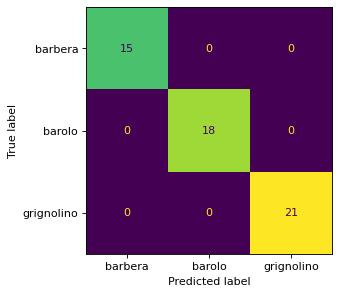

In [6]:
fig, ax = plt.subplots(figsize=(4.5, 4), dpi=80)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, colorbar=False)
plt.show()

## Class probabilities

`predict_proba()` has one column per class, in the order of `classes_`.

In [7]:
model.classes_

array(['barbera', 'barolo', 'grignolino'], dtype='<U10')

In [8]:
proba = model.predict_proba(X_test)
np.round(proba[:5], 3)

array([[0.   , 1.   , 0.   ],
       [0.001, 0.   , 0.999],
       [1.   , 0.   , 0.   ],
       [1.   , 0.   , 0.   ],
       [0.   , 1.   , 0.   ]])

The test points the model is least sure about are the ones where the highest
probability is lowest.

In [9]:
confidence = proba.max(axis=1)
for i in np.argsort(confidence)[:5]:
    print(f"true={y_test[i]:<11} predicted={y_pred[i]:<11} p={confidence[i]:.2f}")

true=grignolino  predicted=grignolino  p=0.47
true=barbera     predicted=barbera     p=1.00
true=barbera     predicted=barbera     p=1.00
true=grignolino  predicted=grignolino  p=1.00
true=grignolino  predicted=grignolino  p=1.00
